# XBoost classification model

## Adatok meta leírása (oszloponként)

- **event_id:** Integer	Az esemény egyedi azonosítója. Egy "event" általában egyetlen beeső részecskét (pl. a protont) és az általa keltett összes másodlagos részecskét jelenti.
- **incoming momentum:**   Primer részecske energiája
- **x, y, z:** Float	A kölcsönhatás (találat) pontos térbeli koordinátái a detektor koordináta-rendszerében (általában mm-ben).
- **hit_energy:**	Float	Az adott lépésben (step) a detektor érzékeny térfogatában leadott teljes energia (Energy Deposit).
- **incoming_theta:** Float. A beeső primer részecske sebességvektorának (vagy impulzusának) polárszöge (zenitszög, $\theta$). Ez adja meg az eltérést a koordináta-rendszer Z-tengelyétől (általában radiánban vagy fokban kifejezve).
- **incoming_phi:** Float. A beeső primer részecske sebességvektorának azimutszöge ($\phi$). Ez a vektor X-Y síkra eső vetületének az X-tengellyel bezárt szöge (szintén radiánban vagy fokban).


### 📏 Geometriai és Térfogati Mutatók

- **width:**	Szélesség	Az X-tengely menti kiterjedés: xmax​−xmin​
- **height:**	Magasság	Az Y-tengely menti kiterjedés: ymax​−ymin​
- **depth:**	Mélység	A Z-tengely menti kiterjedés: zmax​−zmin​
- **depth_range:**	Mélységi tartomány	A detektált események z-irányú szóródásának hossza.
- **volume	Térfogat:**	A pontfelhőt befoglaló test térfogata.

### ⚡ Statisztikai és Súlypont Adatok

- **num_hits:** A beütések (rekordok) száma a vizsgált csoportban.
- **total_hit_energy:** Az összes beütés összesített energiája (∑Ei​).
- **centroid_x, y, z:** A felhő geometriai középpontja. A koordináták számtani közepe: n1​∑xi​.

### 🌐 Gömbi Koordináta-rendszerű Mérőszámok

- **A számítások alapja a középponttól (vagy origótól) mért távolság: r=x2+y2+z2​.
- **mean_r:**   Átlagos radiális távolság. Megmutatja a felhő átlagos távolságát a viszonyítási ponttól.
- **std_r:**    Radiális szórás. A "felhő vastagsága" – minél nagyobb, annál inkább szétterül a pontfelhő a sugár mentén.
- **max_r:**    A legtávolabbi pont távolsága; a felhő külső határa.
- **weighted_r_mean:**  Energia-súlyozott mélység. Ahol az energia-leadás súlypontja elhelyezkedik a sugár mentén.
- **avg_theta:**    Átlagos polárszög (θ). A függőleges (Z) tengelyhez képesti elhajlás; a "kúp" nyílásszögét jellemzi.
- **avg_phi:**  Átlagos azimutszög (ϕ). Az XY síkban mért elfordulás; az oldalirányú orientációt adja meg.
- **angular_spread:**   Szögirányú szóródás. Azt jelzi, mennyire fókuszált vagy "kúpszerű" a felhő.

### 🧬 Sűrűségi és Intenzitási Mutatók
- **numerical_density:**    Beütéssűrűség, num_hits / volume - Az egységnyi térfogatra jutó események (beütések) száma. Megmutatja, mennyire "sűrű" a pontfelhő; a magas érték szorosan pakolt interakciókat jelez.
- **energy_density:**   Energiasűrűség, total_hit_energy / volume - Az egységnyi térfogatban leadott összes energia. Segít azonosítani a nagy intenzitású "hotspotokat" vagy a kiterjedt, de gyenge energia-leadási zónákat.

In [1]:
import os
os.chdir('..')

import core

2026-08-20 15:40:38.126673: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-20 15:40:38.169931: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-20 15:40:39.052312: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
standalone_s1 = core.pd.read_csv('../data/processed/electron/electron_standalone_N100000_M0_20GeV_reg_balanced_aggr_s1_v2.csv')
standalone_s2 = core.pd.read_csv('../data/processed/electron/electron_standalone_N100000_M0_20GeV_reg_balanced_aggr_s2_v2.csv')

print(len(standalone_s1), len(standalone_s2))

99894 99895


In [3]:
standalone_s1.columns

Index(['event_id', 'incoming_momentum', 'incoming_theta', 'incoming_phi',
       'incoming_momentum_bin', 'width', 'height', 'depth', 'depth_range',
       'volume', 'num_hits', 'total_hit_energy', 'centroid_x', 'centroid_y',
       'centroid_z', 'mean_r', 'std_r', 'max_r', 'weighted_r_mean',
       'avg_theta', 'avg_phi', 'angular_spread', 'gnn_logical_node',
       'gnn_arith_node', 'gnn_msg_log_sum', 'gnn_msg_arith_sum',
       'numerical_density', 'energy_density', 'energy'],
      dtype='object')

In [4]:
features = ["width","height","depth","depth_range","volume","num_hits","total_hit_energy",
                   "centroid_x","centroid_y","centroid_z","mean_r","std_r","max_r","weighted_r_mean",
                   "avg_theta","avg_phi","angular_spread","numerical_density","energy_density"]

targets = ["incoming_theta","incoming_phi", "incoming_momentum_bin", "incoming_momentum", "energy"]

In [5]:
def prepare_data(df):
    X = df[features]
    y_momentum = df['incoming_momentum']
    y_angle = df[['incoming_theta', 'incoming_phi']]

    return X, y_momentum, y_angle

X_standalone_s1, y_momentum_standalone_s1, y_angle_standalone_s1 = prepare_data(standalone_s1)
X_standalone_s2, y_momentum_standalone_s2, y_angle_standalone_s2 = prepare_data(standalone_s2)

print(X_standalone_s1.shape, y_momentum_standalone_s1.shape, y_angle_standalone_s1.shape)
print(X_standalone_s2.shape, y_momentum_standalone_s2.shape, y_angle_standalone_s2.shape)

(99894, 19) (99894,) (99894, 2)
(99895, 19) (99895,) (99895, 2)


In [6]:
def train_and_evaluate(X, y, n_splits=5, mark=""):
    # Kényszerítsük mindkettőt NumPy formátumra
    X_arr = core.np.array(X)
    y_arr = core.np.array(y)

    # Regressziónál sima KFold-ot használunk (a StratifiedKFold csak osztályozáshoz jó)
    kf = core.KFold(n_splits=n_splits, shuffle=True, random_state=42)

    # XGBoost Regresszor inicializálása
    xgb_regressor = core.xgb.XGBRegressor(
        objective='reg:squarederror', # Regressziós célfüggvény
        random_state=42, 
        n_estimators=100,
        learning_rate=0.1,
    )

    # Eredmények tárolása
    results = {
        f"MAE_{mark}": [], 
        f"MSE_{mark}": [], 
        f"RMSE_{mark}": [], 
        f"R2_score_{mark}": []
    }

    # Progress bar (tqdm)
    for fold, (train_index, val_index) in core.tqdm(enumerate(kf.split(X_arr))):
        X_train, X_val = X_arr[train_index], X_arr[val_index]
        y_train, y_val = y_arr[train_index], y_arr[val_index]

        # Tanítás
        xgb_regressor.fit(X_train, y_train)

        # Predikció (folytonos értékek)
        y_pred = xgb_regressor.predict(X_val)

        # Regressziós metrikák számítása
        mae = core.mean_absolute_error(y_val, y_pred)
        mse = core.mean_squared_error(y_val, y_pred)
        rmse = core.np.sqrt(mse)
        r2 = core.r2_score(y_val, y_pred)

        # Mentés
        results[f"MAE_{mark}"].append(mae)
        results[f"MSE_{mark}"].append(mse)
        results[f"RMSE_{mark}"].append(rmse)
        results[f"R2_score_{mark}"].append(r2)

    return core.pd.DataFrame(results)

In [7]:
results_momentum_standalone_s1 = train_and_evaluate(X_standalone_s1, y_momentum_standalone_s1, mark="IM")
results_momentum_standalone_s2 = train_and_evaluate(X_standalone_s2, y_momentum_standalone_s2, mark="IM")

5it [00:01,  3.71it/s]
5it [00:01,  4.22it/s]


In [8]:
results_angle_standalone_s1 = train_and_evaluate(X_standalone_s1, y_angle_standalone_s1, mark="IA")
results_angle_standalone_s2 = train_and_evaluate(X_standalone_s2, y_angle_standalone_s2, mark="IA")

5it [00:02,  2.32it/s]
5it [00:02,  2.31it/s]


## K-Fold (k=5) kereszt validáció mérési eredménye

In [9]:
results_momentum_standalone_s1

,MAE_IM,MSE_IM,RMSE_IM,R2_score_IM
0,0.677214,1.184445,1.088322,0.964375
1,0.683748,1.237758,1.112546,0.963117
2,0.677868,1.186278,1.089164,0.963953
3,0.678793,1.180554,1.086533,0.964005
4,0.679554,1.209376,1.099716,0.963981


In [10]:
results_momentum_standalone_s2

,MAE_IM,MSE_IM,RMSE_IM,R2_score_IM
0,0.667777,1.137711,1.066635,0.965745
1,0.681113,1.232121,1.110009,0.962630
2,0.674654,1.164309,1.079031,0.965217
3,0.684173,1.240409,1.113736,0.962973
4,0.673534,1.158995,1.076566,0.964867


In [11]:
results_angle_standalone_s1

,MAE_IA,MSE_IA,RMSE_IA,R2_score_IA
0,0.040774,0.063827,0.252640,0.973323
1,0.042762,0.068771,0.262242,0.971442
2,0.040431,0.063395,0.251784,0.973757
3,0.041124,0.061625,0.248243,0.975357
4,0.041396,0.061200,0.247386,0.973838


In [12]:
results_angle_standalone_s2

,MAE_IA,MSE_IA,RMSE_IA,R2_score_IA
0,0.041154,0.062028,0.249054,0.974264
1,0.041156,0.062043,0.249085,0.974636
2,0.039915,0.060662,0.246297,0.974483
3,0.042281,0.064964,0.254881,0.972546
4,0.040784,0.061325,0.247639,0.974813


In [13]:
def train_and_eval_by_energy(df, scenario_name, features, labels):
    
    # 2. Tanító és Validációs halmaz szétválasztása
    train_df, val_df = core.train_test_split(df, test_size=0.2, random_state=42)
    
    # 3. Modell tanítása (Az XGBRegressor támogatja a multi-target regressziót)
    model = core.xgb.XGBRegressor(
        objective='reg:squarederror', 
        random_state=42, 
        n_estimators=100,
        learning_rate=0.1,
    )
    model.fit(train_df[features], train_df[labels])
    
    # 4. Predikció a validációs halmazra
    val_df = val_df.copy() 
    
    # Dinamikus predikciós oszlopnevek generálása (pl. 'pred_incoming_phi', 'pred_incoming_theta')
    pred_cols = [f'pred_{label}' for label in labels]
    predictions = model.predict(val_df[features])
    
    # A Pandas értékadás 1D és 2D tömbök esetén eltérhet, ezt biztonságosan kezeljük
    if len(labels) == 1:
        val_df[pred_cols[0]] = predictions
    else:
        val_df[pred_cols] = predictions
        
    # 5. Pontosság számítása binenként és label-enként
    # Az axis=0 használatával a Pandas automatikusan végigmegy az összes label oszlopon.
    # Az eredmény DataFrame-ek oszlopai maguk a labelek lesznek.
    
    # RMSE
    bin_rmse_results = val_df.groupby('incoming_momentum_bin').apply(
        lambda x: core.np.sqrt(((x[labels] - x[pred_cols].values)**2).mean(axis=0))
    )
    
    # Átlagos abszolút különbség (MAE)
    bin_diff_results = val_df.groupby('incoming_momentum_bin').apply(
        lambda x: abs(x[labels] - x[pred_cols].values).mean(axis=0)
    )

    # Átlagos relatív különbség (%)
    bin_relative_diff_results = val_df.groupby('incoming_momentum_bin').apply(
        lambda x: (abs(x[labels] - x[pred_cols].values) / x[labels]).mean(axis=0) * 100
    )
    
    return bin_rmse_results, bin_diff_results, bin_relative_diff_results, model, val_df

In [14]:
# Lefuttatjuk a 4 különböző esetre (feltételezve, hogy az adatok be vannak töltve)
standalone_momentum_s1_rmse_results, standalone_momentum_s1_diff_results, standalone_momentum_s1_relative_diff_results, standalone_momentum_s1_model, standalone_momentum_s1_val_df = train_and_eval_by_energy(standalone_s1, 'Standalone S1', features, ["incoming_momentum"])
standalone_momentum_s2_rmse_results, standalone_momentum_s2_diff_results, standalone_momentum_s2_relative_diff_results, standalone_momentum_s2_model, standalone_momentum_s2_val_df = train_and_eval_by_energy(standalone_s2, 'Standalone S2', features, ["incoming_momentum"])

results_momentum_rmse = {
    'Standalone S1': standalone_momentum_s1_rmse_results,
    'Standalone S2': standalone_momentum_s2_rmse_results
}

results_momentum_diff = {
    'Standalone S1': standalone_momentum_s1_diff_results,
    'Standalone S2': standalone_momentum_s2_diff_results
}

results_momentum_relative_diff = {
    'Standalone S1': standalone_momentum_s1_relative_diff_results,
    'Standalone S2': standalone_momentum_s2_relative_diff_results
}

/tmp/ipykernel_280751/2262894671.py:33: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bin_rmse_results = val_df.groupby('incoming_momentum_bin').apply(
/tmp/ipykernel_280751/2262894671.py:38: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bin_diff_results = val_df.groupby('incoming_momentum_bin').apply(
/tmp/ipykernel_280751/2262894671.py:43: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This

In [15]:
# Lefuttatjuk a 4 különböző esetre (feltételezve, hogy az adatok be vannak töltve)
standalone_angle_s1_rmse_results, standalone_angle_s1_diff_results, standalone_angle_s1_relative_diff_results, standalone_angle_s1_model, standalone_angle_s1_val_df = train_and_eval_by_energy(standalone_s1, 'Standalone S1', features, ["incoming_phi", "incoming_theta"])
standalone_angle_s2_rmse_results, standalone_angle_s2_diff_results, standalone_angle_s2_relative_diff_results, standalone_angle_s2_model, standalone_angle_s2_val_df = train_and_eval_by_energy(standalone_s2, 'Standalone S2', features, ["incoming_phi", "incoming_theta"])

results_angle_rmse = {
    'Standalone S1': standalone_angle_s1_rmse_results,
    'Standalone S2': standalone_angle_s2_rmse_results
}

results_angle_diff = {
    'Standalone S1': standalone_angle_s1_diff_results,
    'Standalone S2': standalone_angle_s2_diff_results
}

results_angle_relative_diff = {
    'Standalone S1': standalone_angle_s1_relative_diff_results,
    'Standalone S2': standalone_angle_s2_relative_diff_results
}

/tmp/ipykernel_280751/2262894671.py:33: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bin_rmse_results = val_df.groupby('incoming_momentum_bin').apply(
/tmp/ipykernel_280751/2262894671.py:38: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bin_diff_results = val_df.groupby('incoming_momentum_bin').apply(
/tmp/ipykernel_280751/2262894671.py:43: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This

In [16]:
def _plot_bars_on_ax(ax, results_dict, title, y_label):
    """Segédfüggvény, amely egy megadott Matplotlib Axis (ax) objektumra rajzolja az oszlopdiagramot."""
    # Összes bin összegyűjtése az X tengelyhez
    all_bins = sorted(list(set().union(*(res.index for res in results_dict.values()))))
    
    x = core.np.arange(len(all_bins))  # Bin helyzetek
    width = 0.8 / len(results_dict)    # Oszlopok szélessége dinamikusan
    
    # Oszlopok kirajzolása eltolással
    for i, (name, data) in enumerate(results_dict.items()):
        if isinstance(data, core.pd.DataFrame):
            y_values = data.reindex(all_bins).iloc[:, 0].fillna(0).values
        else:
            y_values = data.reindex(all_bins).fillna(0).values
            
        offset = (i - len(results_dict) / 2 + 0.5) * width
        ax.bar(x + offset, y_values, width, label=name)

    # Tengelyek és feliratok beállítása a kapott 'ax' objektumon
    ax.set_xlabel('Energia bin (incoming_momentum_bin)', fontsize=10)
    ax.set_ylabel(y_label, fontsize=10)
    ax.set_title(title, fontsize=12)
    ax.set_xticks(x)
    ax.set_xticklabels(all_bins)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.legend(loc='best')

def plot_all_metrics_grid(results_rmse, results_diff, results_relative):
    """Főfüggvény, amely létrehozza a 2 soros elrendezést és meghívja a segédfüggvényt."""
    # Létrehozunk egy elég nagy ábrát, hogy minden elférjen
    fig = core.plt.figure(figsize=(16, 12))
    
    # --- 1. SOR: Bal oldali ábra (RMSE) ---
    ax1 = fig.add_subplot(2, 2, 1) # 2 sor, 2 oszlop, 1. pozíció
    _plot_bars_on_ax(ax1, results_rmse, 'RMSE Pontosság', 'RMSE')
    
    # --- 1. SOR: Jobb oldali ábra (Diff / MAE) ---
    ax2 = fig.add_subplot(2, 2, 2) # 2 sor, 2 oszlop, 2. pozíció
    _plot_bars_on_ax(ax2, results_diff, 'Átlagos Abszolút Hiba (MAE)', 'Eltérés')
    
    # --- 2. SOR: Alsó, összevont ábra (Relatív Diff) ---
    ax3 = fig.add_subplot(2, 1, 2) # 2 sor, 1 oszlop (tehát szélesebb), 2. pozíció
    _plot_bars_on_ax(ax3, results_relative, 'Relatív Hiba', 'Eltérés (%)')
    
    # Térközök automatikus optimalizálása, hogy ne fedjék egymást a feliratok
    core.plt.tight_layout()
    core.plt.show()

# Futtatás a te adataiddal:
# 

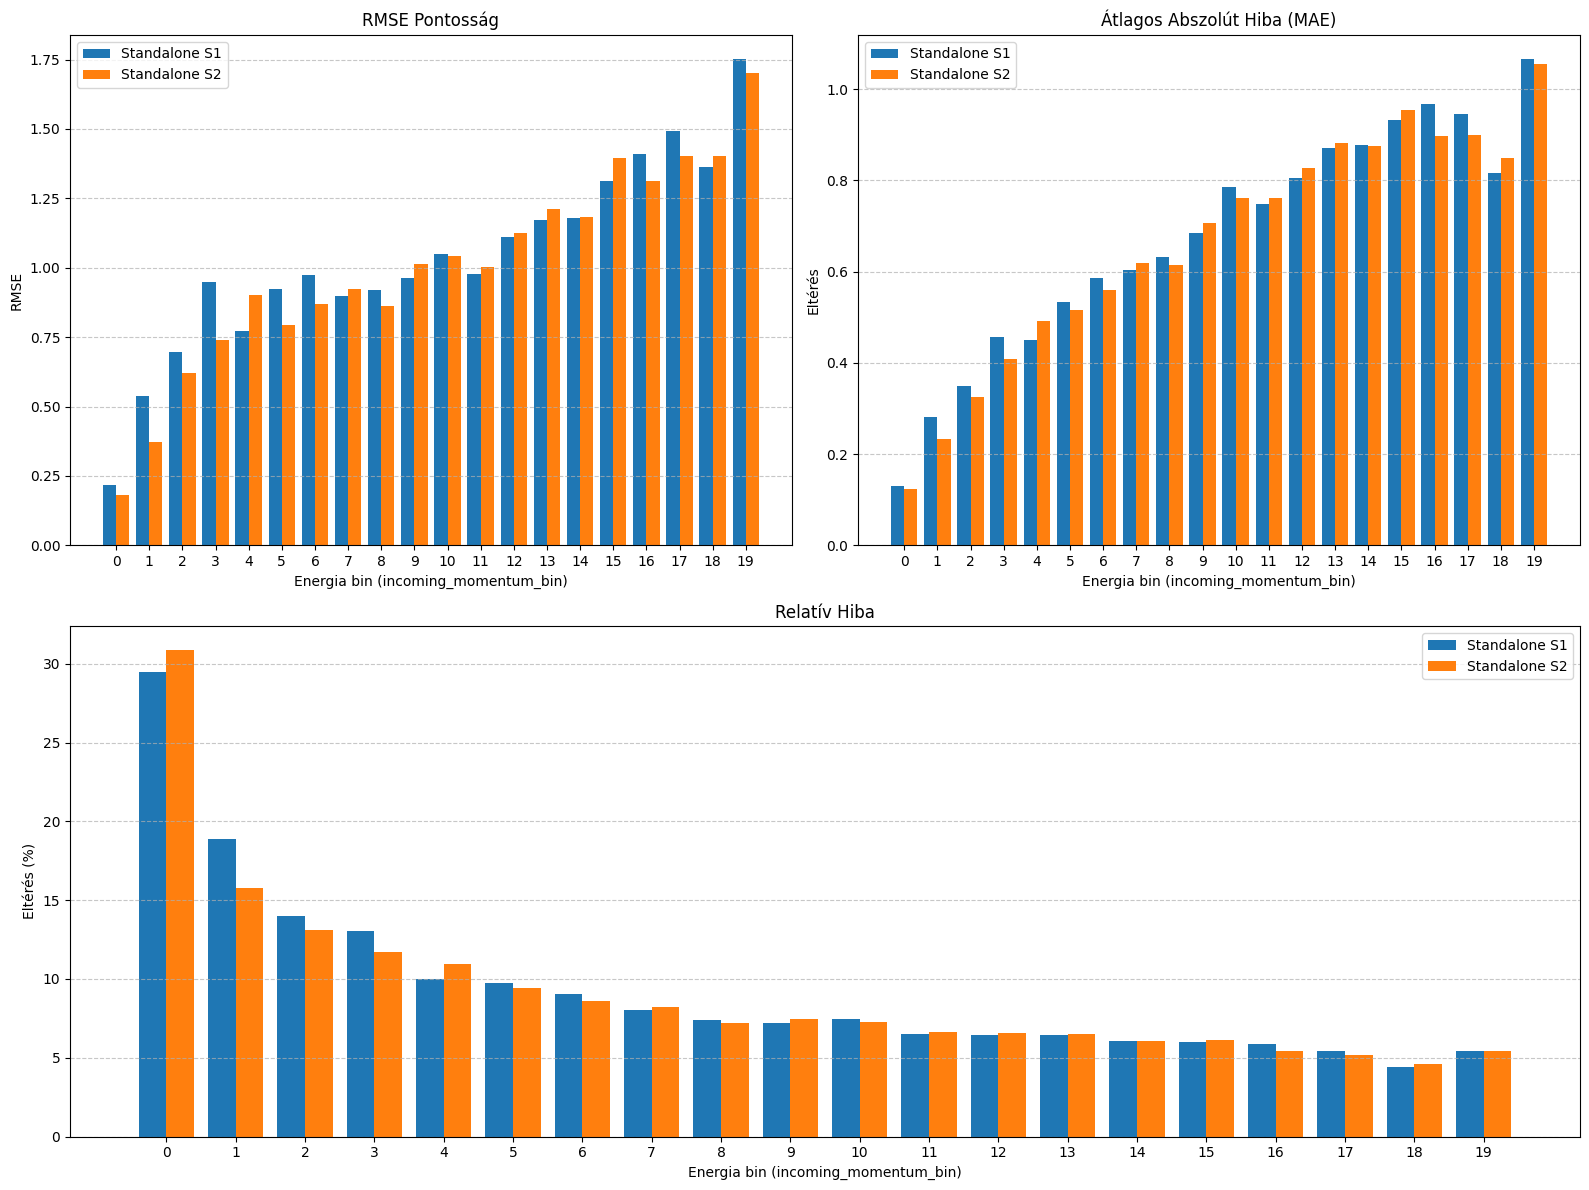

In [17]:
plot_all_metrics_grid(results_momentum_rmse, results_momentum_diff, results_momentum_relative_diff)

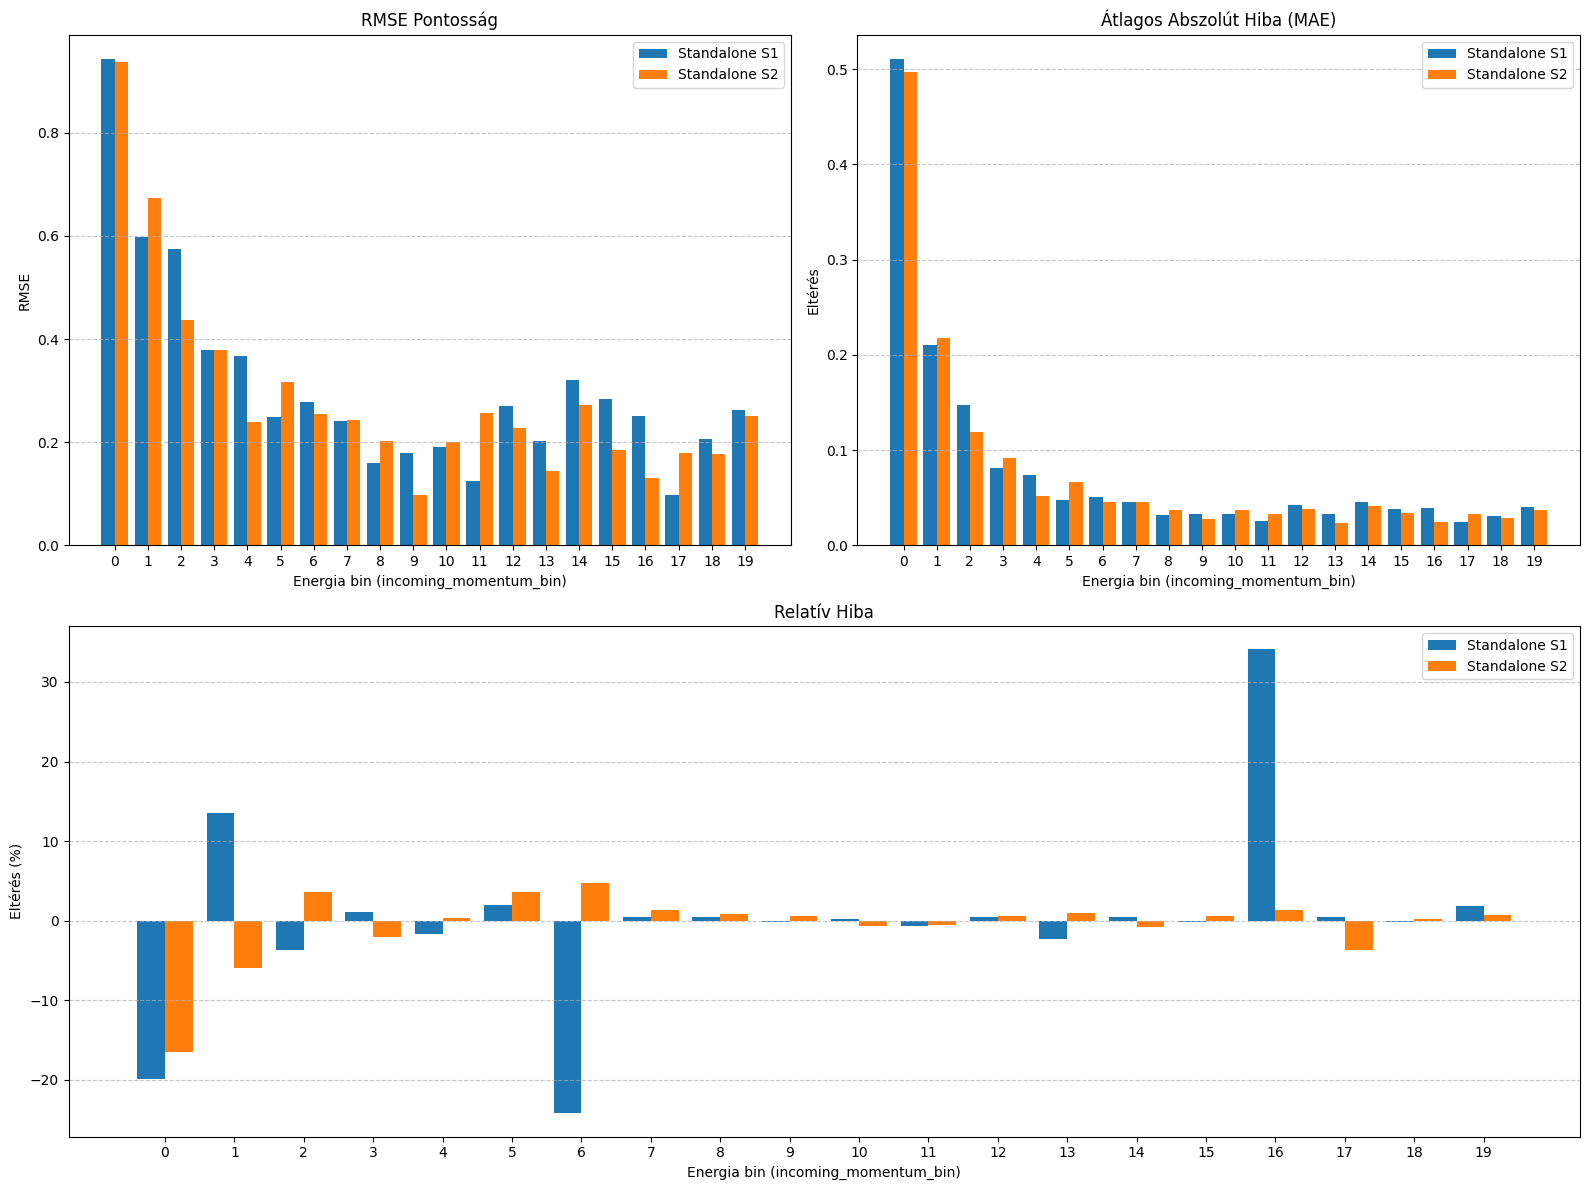

In [18]:
plot_all_metrics_grid(results_angle_rmse, results_angle_diff, results_angle_relative_diff)

In [19]:
def evaluate_binary_performance(model, df, features, scenario_name):
    # 1. Speciális validációs halmaz összeállítása
    # Class 0: energia < 2
    class_0_pool = df[df['incoming_momentum'] < 2]
    
    # Class 1: energia > 2, de a kérés szerint jellemzően > 10
    class_1_pool = df[df['incoming_momentum'] > 10]
    
    # Ha nincs elég adat a > 10 tartományban, vegyünk a > 2-ből is
    if len(class_1_pool) < 50: 
        class_1_pool = df[df['incoming_momentum'] > 2]

    # Cél: 95% Class 0 és 5% Class 1 arány
    # Meghatározzuk a mintaszámot (például összesen 2000 elem)
    total_samples = 2000
    n_0 = int(total_samples * 0.99)
    n_1 = int(total_samples * 0.01)

    # Mintavételezés (ha van elég adat, ha nincs, az összeset vesszük)
    s_0 = class_0_pool.sample(min(n_0, len(class_0_pool)), random_state=42)
    s_1 = class_1_pool.sample(min(n_1, len(class_1_pool)), random_state=42)
    
    val_special = core.pd.concat([s_0, s_1]).sample(frac=1, random_state=42) # összekeverés
    
    y_true_binary = (val_special['incoming_momentum'] > 2).astype(int)

    # 3. Futtatás a regressziós modellen
    y_pred_continuous = model.predict(val_special[features])

    # 4. Regressziós kimenet konvertálása binárissá
    # Mivel a határ 2 GeV-nél van, a modell jóslatát is 2-nél vágjuk el
    y_pred_binary = (y_pred_continuous > 2).astype(int)

    # 5. Metrikák mérése
    metrics = {
        "Scenario": scenario_name,
        "Accuracy": core.accuracy_score(y_true_binary, y_pred_binary),
        "Balanced Accuracy": core.balanced_accuracy_score(y_true_binary, y_pred_binary),
        "Precision": core.precision_score(y_true_binary, y_pred_binary, zero_division=0, average='weighted'),
        "Recall": core.recall_score(y_true_binary, y_pred_binary, zero_division=0, average='weighted'),
        "F1-Score": core.f1_score(y_true_binary, y_pred_binary, zero_division=0, average='weighted'),
        "Class_0_count": len(s_0),
        "Class_1_count": len(s_1)
    }
    
    return metrics

In [20]:
results_standalone_binary_momentum_s1 = core.pd.DataFrame([evaluate_binary_performance(standalone_momentum_s1_model, standalone_momentum_s1_val_df, features, 'Standalone S1')])
results_standalone_binary_momentum_s2 = core.pd.DataFrame([evaluate_binary_performance(standalone_momentum_s2_model, standalone_momentum_s2_val_df, features, 'Standalone S2')])

## Pontosság asszimetrikus adathalmazon

In [21]:
results_standalone_binary_momentum_s1.set_index('Scenario', inplace=True)
results_standalone_binary_momentum_s1.T

Scenario,Standalone S1
Accuracy,0.908543
Balanced Accuracy,0.953807
Precision,0.990945
Recall,0.908543
F1-Score,0.943817
Class_0_count,1970.000000
Class_1_count,20.000000


In [22]:
results_standalone_binary_momentum_s2.set_index('Scenario', inplace=True)
results_standalone_binary_momentum_s2.T

Scenario,Standalone S2
Accuracy,0.932500
Balanced Accuracy,0.965909
Precision,0.991290
Recall,0.932500
F1-Score,0.957345
Class_0_count,1980.000000
Class_1_count,20.000000


In [23]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

def surrogate_tree_visualization(df, model, features, scenario_name):    
    # Az XGBoost modellünkkel készítünk predikciókat (ezek lesznek a szurrogát modell célértékei)
    y_proxy = model.predict(df[features]) 

    # 2. Szurrogát Döntési Fa tanítása (Regressziós fa)
    # A max_depth=3 segít abban, hogy a fa értelmezhető (lepárolt) maradjon
    surrogate_tree = DecisionTreeRegressor(max_depth=3, random_state=42) 
    surrogate_tree.fit(df[features], y_proxy)

    # 3. A szurrogát fa hűségének (fidelity) mérése
    # Regressziónál az R2 score mutatja meg, hogy a fa a variancia hány %-át fedi le
    y_surrogate_pred = surrogate_tree.predict(df[features])
    fidelity_r2 = core.r2_score(y_proxy, y_surrogate_pred)
    mae_diff = core.mean_absolute_error(y_proxy, y_surrogate_pred)

    print(f"--- {scenario_name} ---")
    print(f"Szurrogát fa hűsége (R2 score): {fidelity_r2:.4f}")
    print(f"Átlagos eltérés az XGBoost-tól (MAE): {mae_diff:.4f} GeV")

    # 4. Megjelenítés
    core.plt.figure(figsize=(22, 10))
    plot_tree(
        surrogate_tree, 
        feature_names=features, 
        filled=True, 
        rounded=True, 
        fontsize=11,
        precision=2 # Tizedesjegyek száma a csomópontokban
    )
    core.plt.title(f"XGBoost Regressor Szurrogát Fa - {scenario_name}\n(Fidelity R²: {fidelity_r2:.4f})", fontsize=16)
    
    # Mentés és megjelenítés
    file_name = f'surrogate_tree_{scenario_name.replace(" ", "_")}.png'
    core.plt.savefig(file_name, bbox_inches='tight')
    core.plt.show()

--- Standalone S1 Incoming Momentum ---
Szurrogát fa hűsége (R2 score): 0.9372
Átlagos eltérés az XGBoost-tól (MAE): 1.0111 GeV


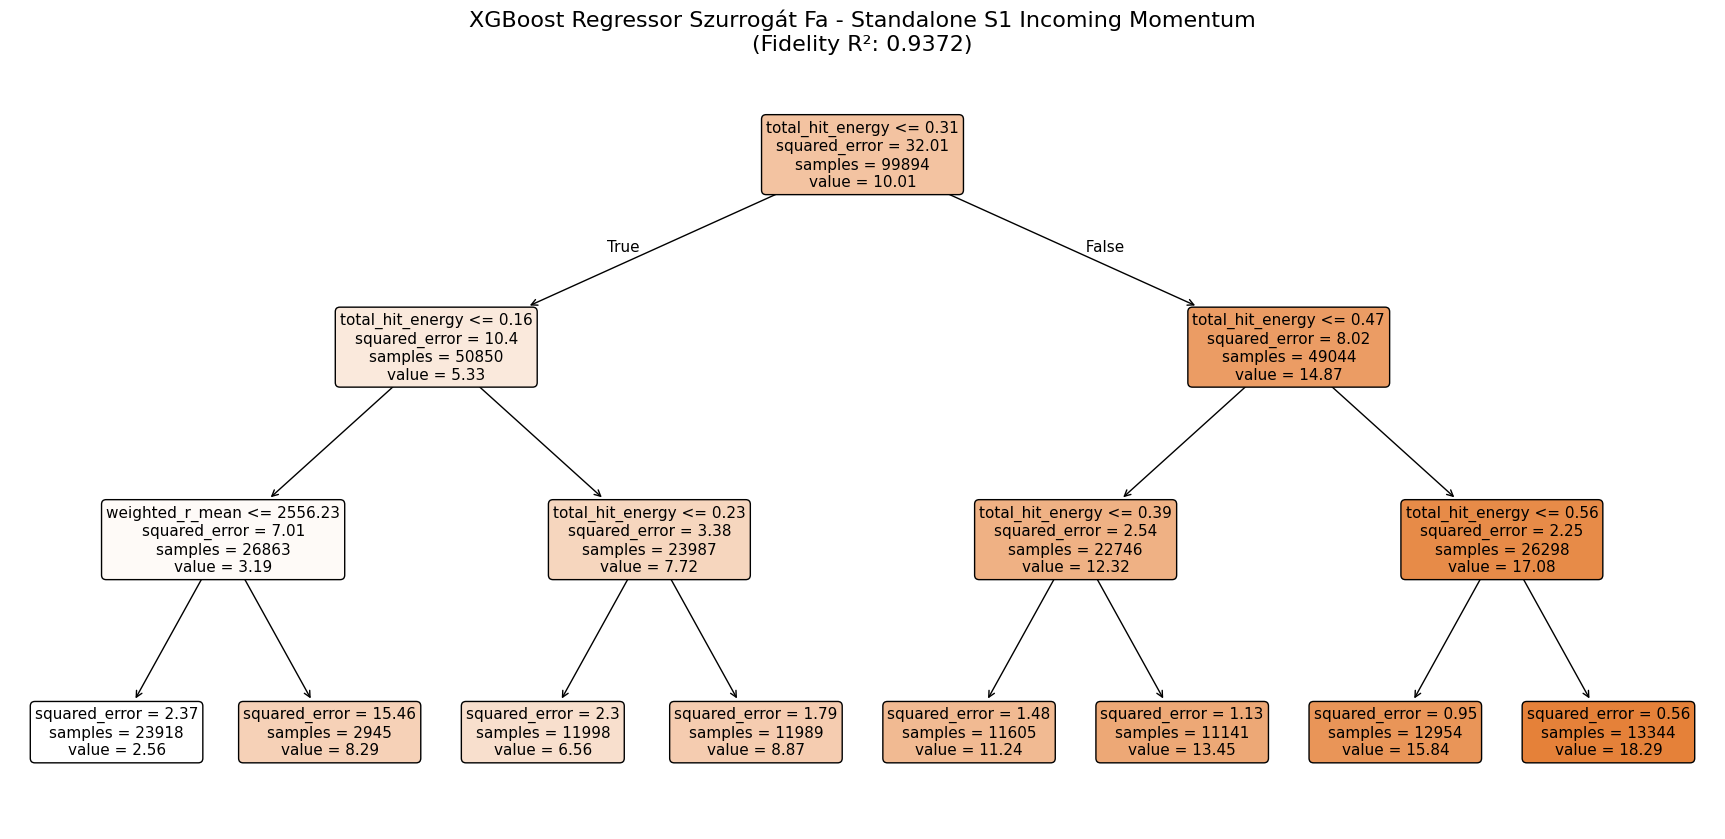

In [24]:
surrogate_tree_visualization(standalone_s1, standalone_momentum_s1_model, features, 'Standalone S1 Incoming Momentum')

--- Standalone S2 Incoming Momentum ---
Szurrogát fa hűsége (R2 score): 0.9372
Átlagos eltérés az XGBoost-tól (MAE): 1.0121 GeV


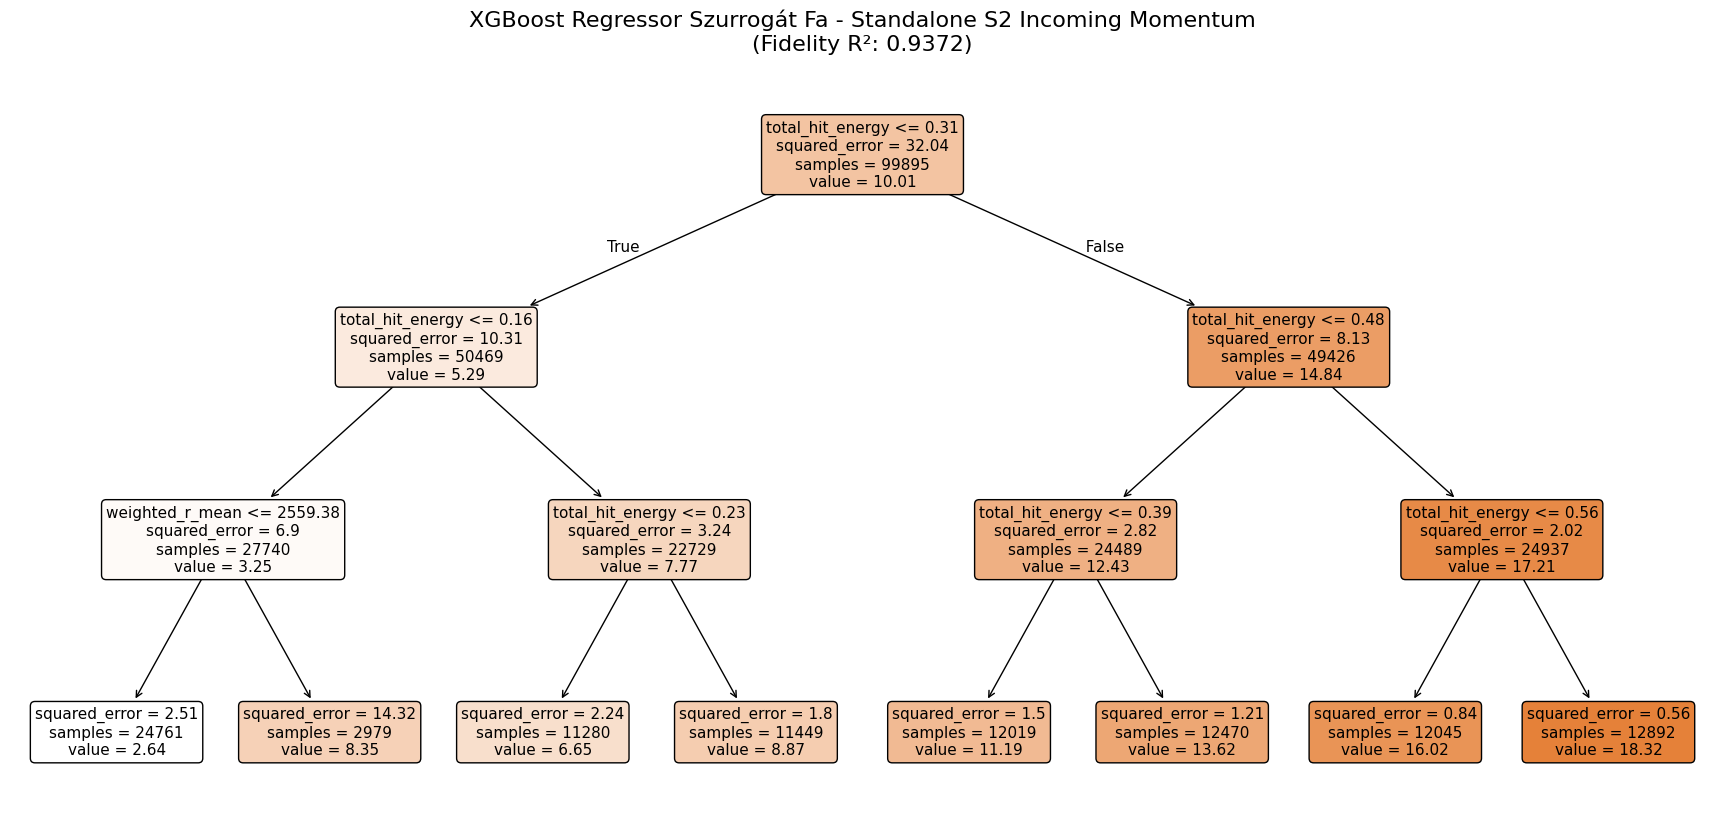

In [25]:
surrogate_tree_visualization(standalone_s2, standalone_momentum_s2_model, features, 'Standalone S2 Incoming Momentum')

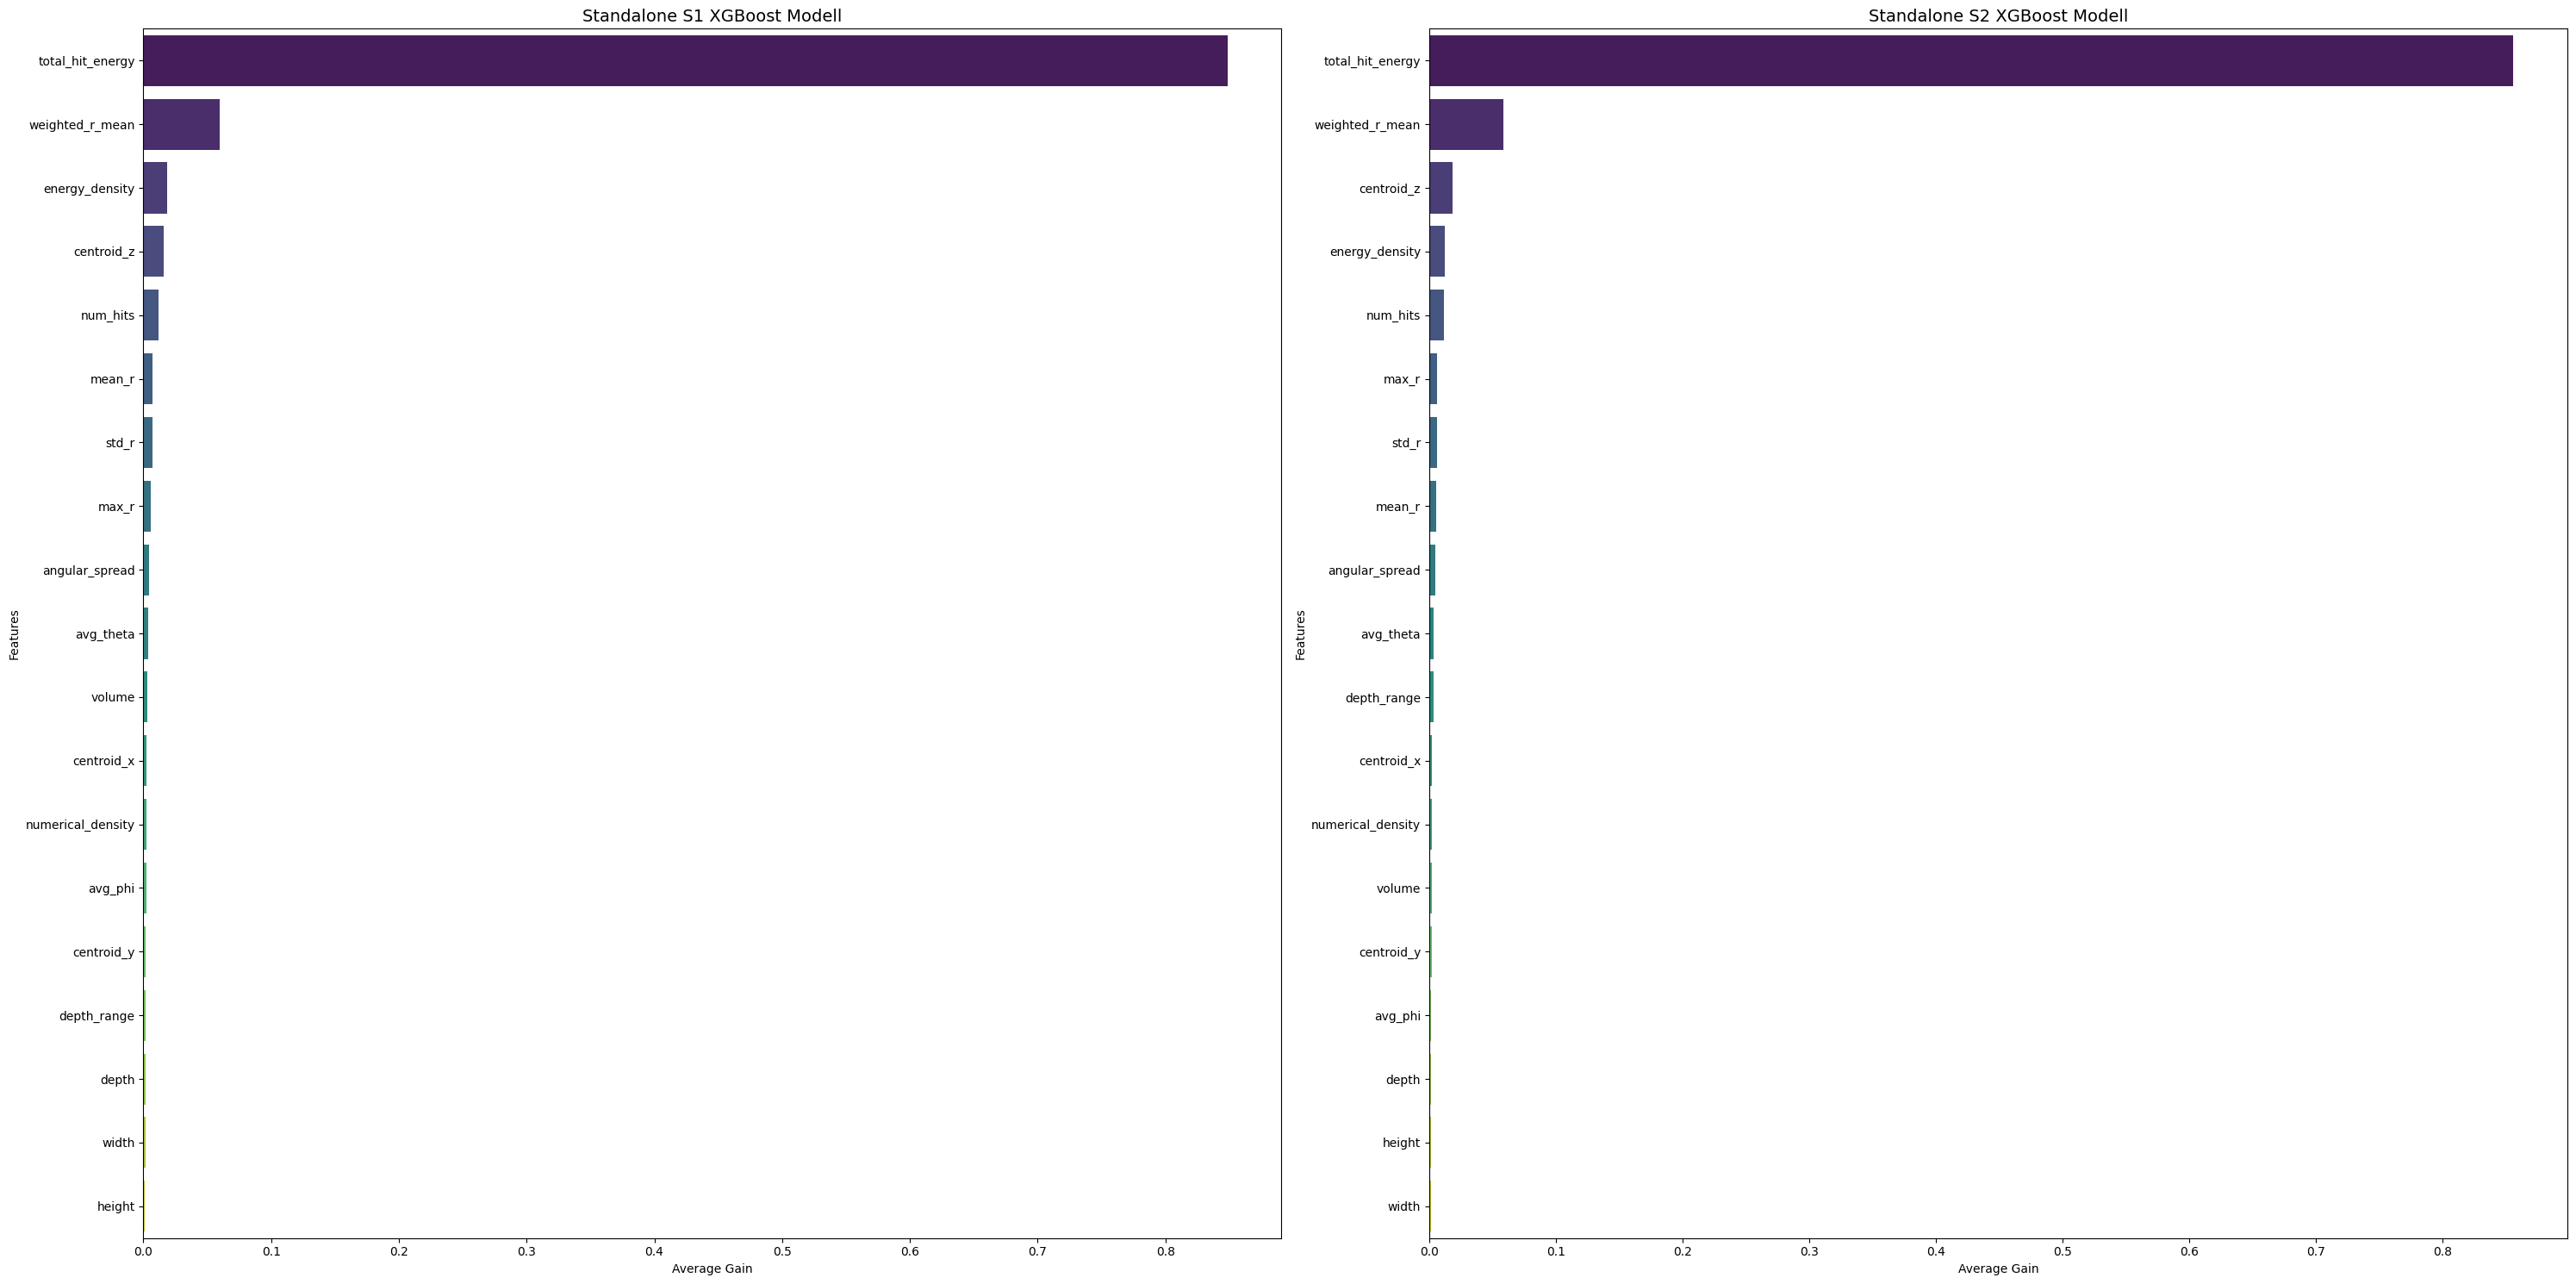

In [26]:
standalone_s1_imp = core.pd.Series(standalone_momentum_s1_model.feature_importances_, index=features).sort_values(ascending=False)
standalone_s2_imp = core.pd.Series(standalone_momentum_s2_model.feature_importances_, index=features).sort_values(ascending=False)

# Vizualizáció egy sorban, két oszlopban
fig, axes = core.plt.subplots(1, 2, figsize=(30, 15), sharey=False)

core.sns.barplot(x=standalone_s1_imp.values, y=standalone_s1_imp.index, hue=standalone_s1_imp.index, palette='viridis', legend=False,ax=axes[0])
axes[0].set_title('Standalone S1 XGBoost Modell', fontsize=14)
axes[0].set_xlabel('Average Gain')
axes[0].set_ylabel('Features')

core.sns.barplot(x=standalone_s2_imp.values, y=standalone_s2_imp.index, hue=standalone_s2_imp.index, palette='viridis', legend=False,ax=axes[1])
axes[1].set_title('Standalone S2 XGBoost Modell', fontsize=14)
axes[1].set_xlabel('Average Gain')
axes[1].set_ylabel('Features')


core.plt.tight_layout()
core.plt.show()

--- Standalone S1 Angle ---
Szurrogát fa hűsége (R2 score): 0.4440
Átlagos eltérés az XGBoost-tól (MAE): 0.2315 GeV


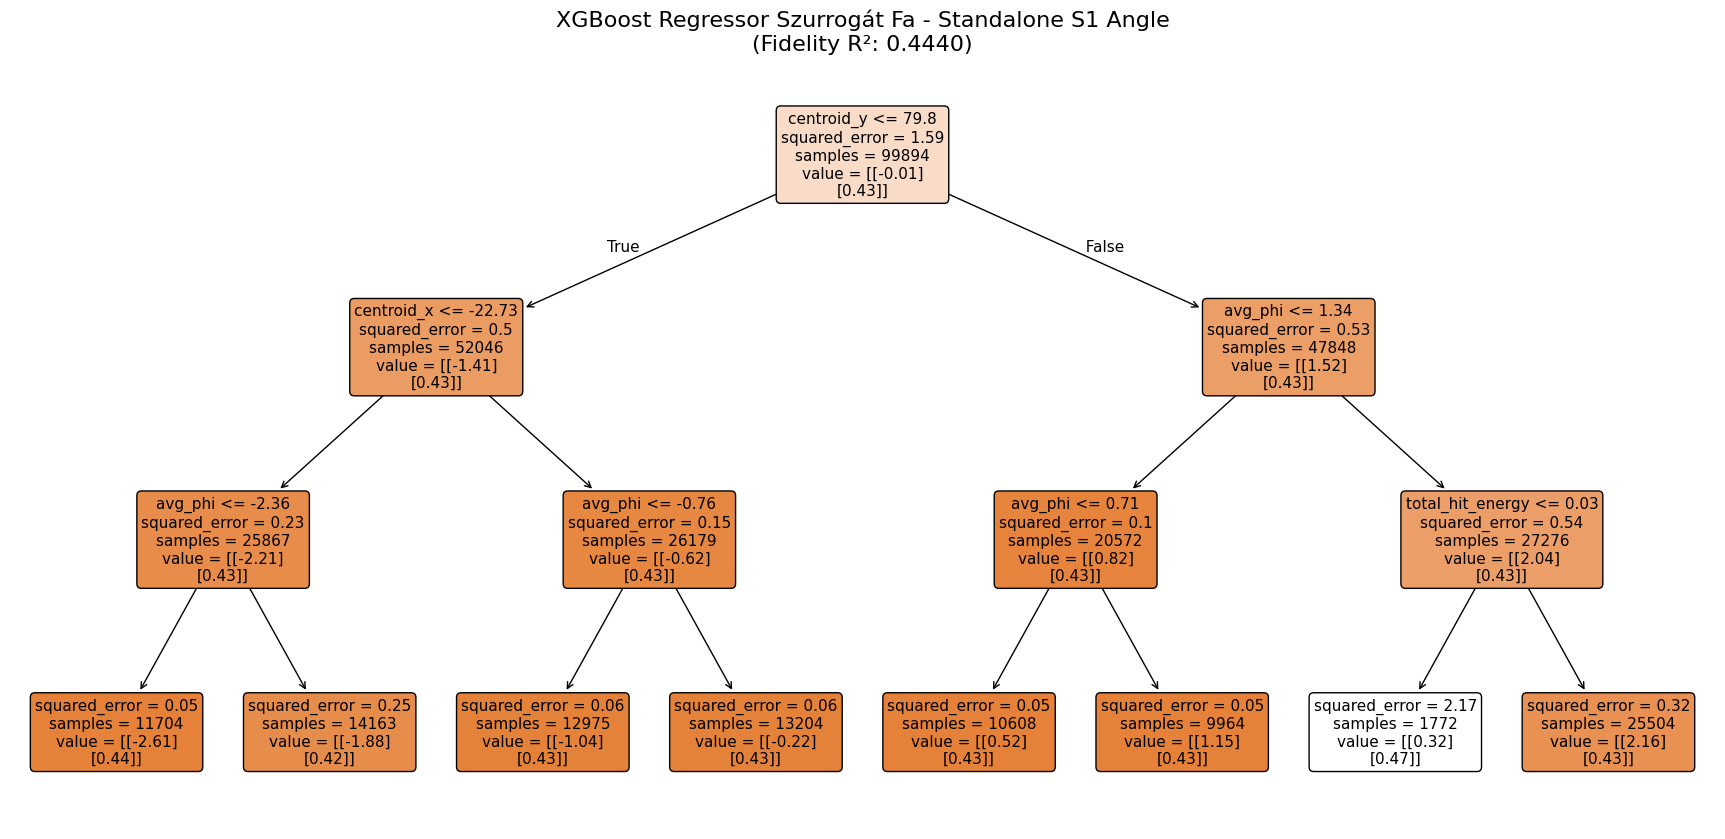

In [27]:
surrogate_tree_visualization(standalone_s1, standalone_angle_s1_model, features, 'Standalone S1 Angle')

--- Standalone S2 Angle ---
Szurrogát fa hűsége (R2 score): 0.4463
Átlagos eltérés az XGBoost-tól (MAE): 0.2308 GeV


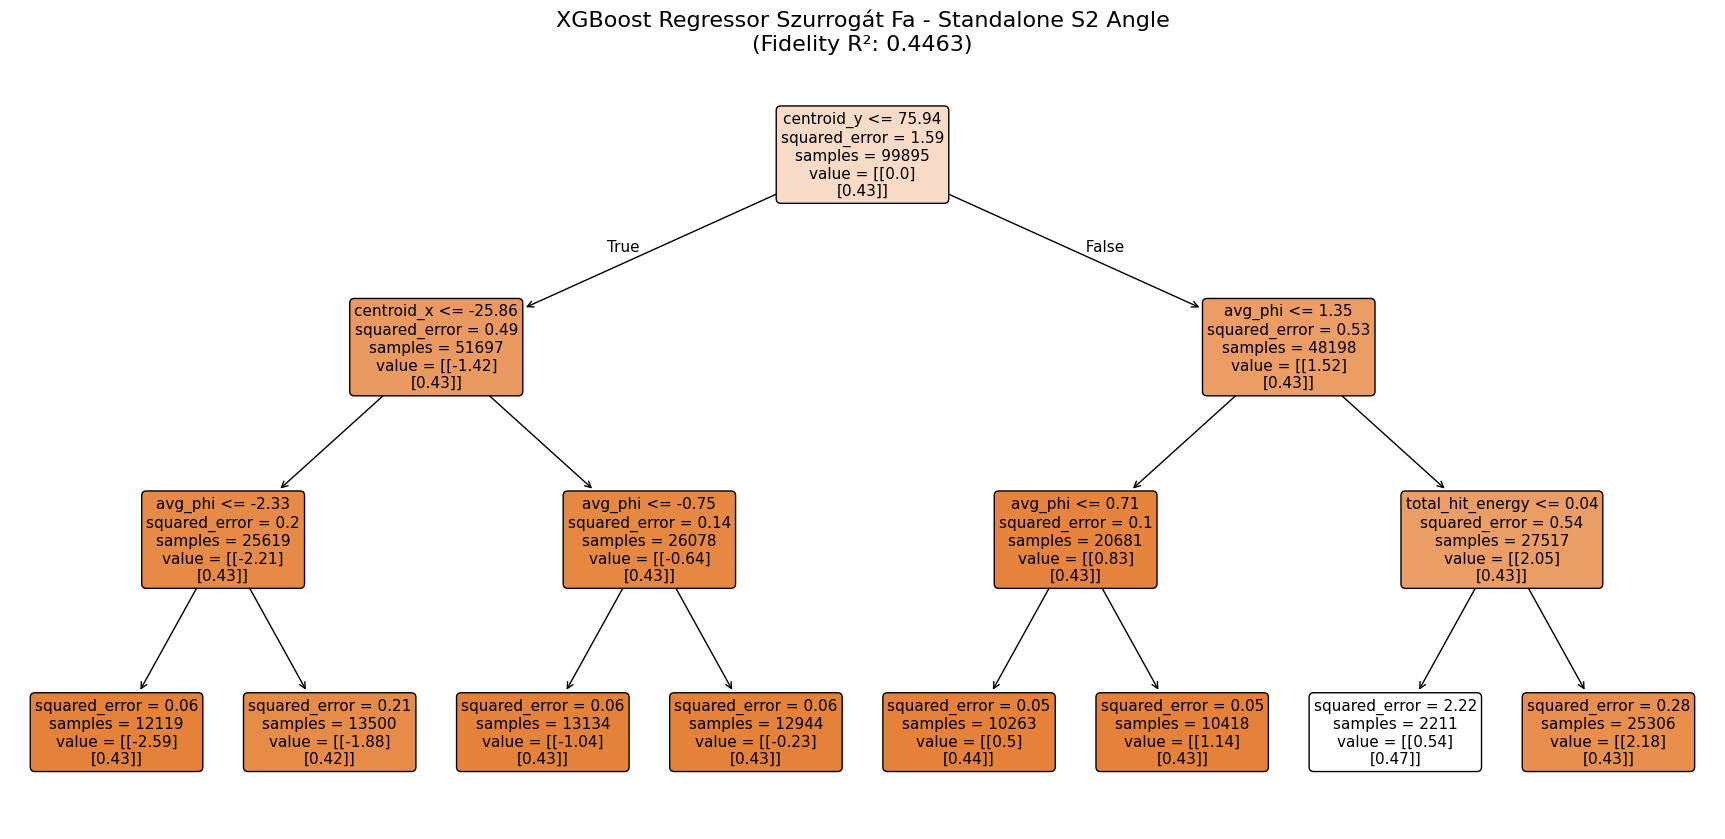

In [28]:
surrogate_tree_visualization(standalone_s2, standalone_angle_s2_model, features, 'Standalone S2 Angle')

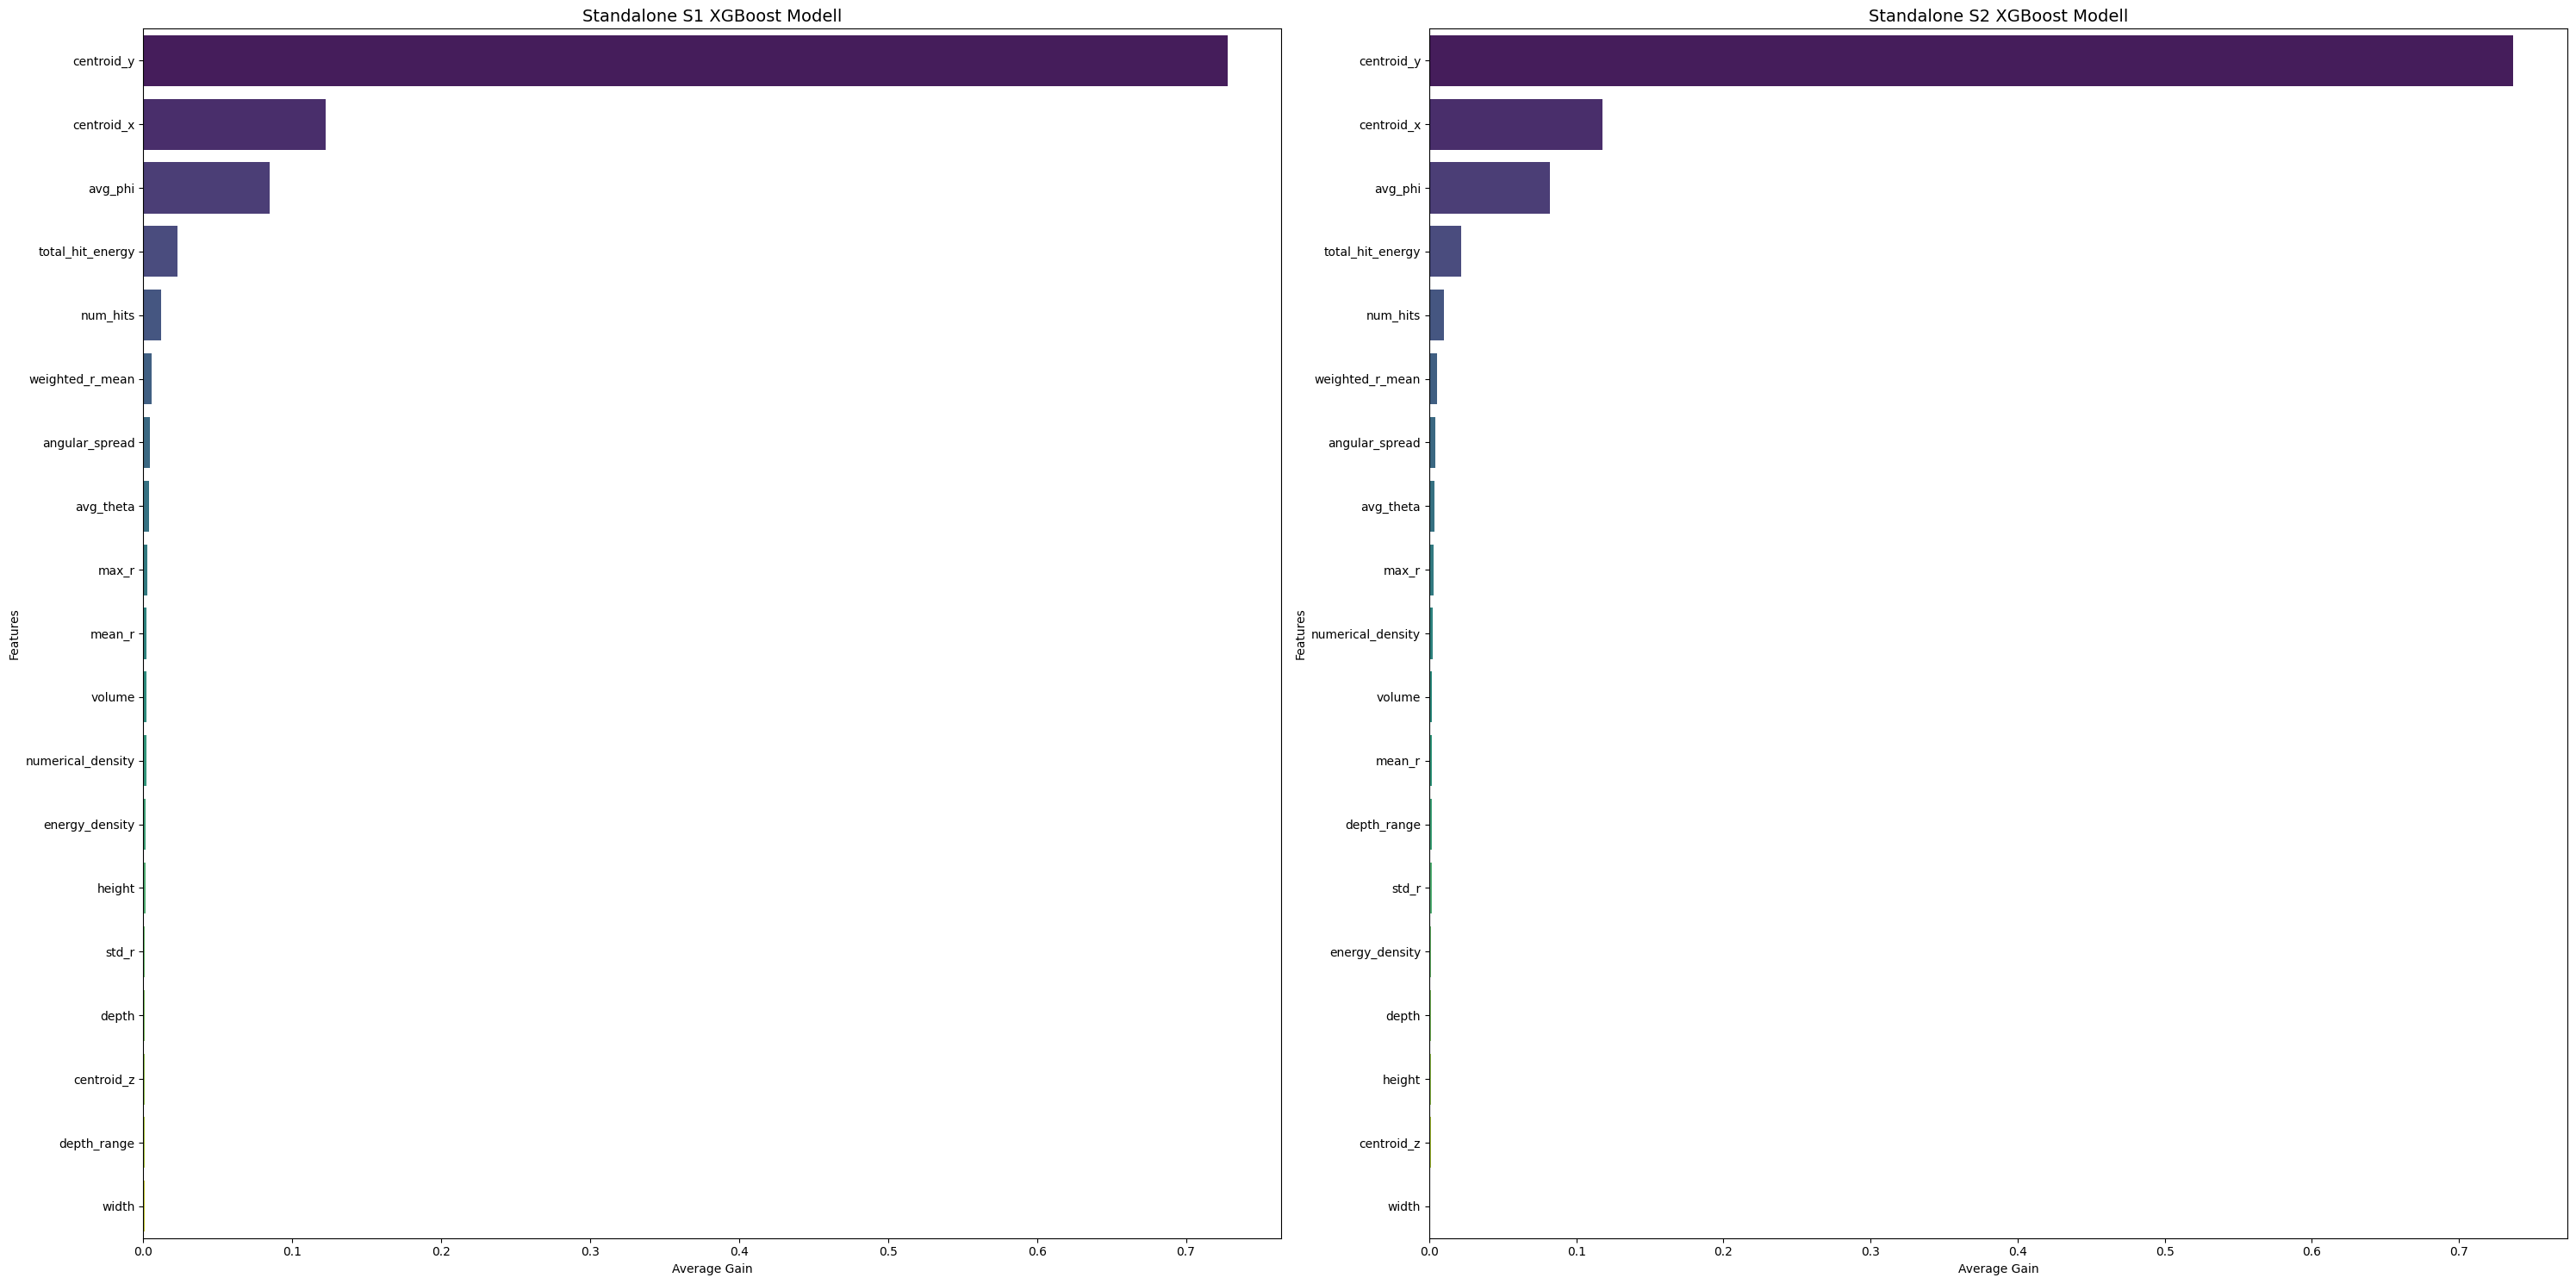

In [29]:
standalone_s1_imp = core.pd.Series(standalone_angle_s1_model.feature_importances_, index=features).sort_values(ascending=False)
standalone_s2_imp = core.pd.Series(standalone_angle_s2_model.feature_importances_, index=features).sort_values(ascending=False)

# Vizualizáció egy sorban, két oszlopban
fig, axes = core.plt.subplots(1, 2, figsize=(30, 15), sharey=False)

core.sns.barplot(x=standalone_s1_imp.values, y=standalone_s1_imp.index, hue=standalone_s1_imp.index, palette='viridis', legend=False,ax=axes[0])
axes[0].set_title('Standalone S1 XGBoost Modell', fontsize=14)
axes[0].set_xlabel('Average Gain')
axes[0].set_ylabel('Features')

core.sns.barplot(x=standalone_s2_imp.values, y=standalone_s2_imp.index, hue=standalone_s2_imp.index, palette='viridis', legend=False,ax=axes[1])
axes[1].set_title('Standalone S2 XGBoost Modell', fontsize=14)
axes[1].set_xlabel('Average Gain')
axes[1].set_ylabel('Features')


core.plt.tight_layout()
core.plt.show()